# Using DGPs

A DGP (`badgers.core.dgp`) carries the causal graph plus one fitted
mechanism per node and exposes `fit`/`sample`/`intervene`. The only
shipped backends are two adapters that wrap externally built
structural causal models:

| Backend | Extra | Wraps | Documentation |
|---|---|---|---|
| `GcmSCMDGP` | `badgers[dowhy]` | a `dowhy.gcm.StructuralCausalModel` | [dowhy.gcm](https://www.pywhy.org/dowhy/v0.9.1/user_guide/gcm_based_inference/draw_samples.html) |
| `PyMCSCMDGP` | `badgers[pymc]` | a PyMC `pm.Model` (structural nodes observed) | [pymc](https://www.pymc.io/projects/examples/en/latest/causal_inference/interventional_distribution.html) |




## Fit and sample

- Here we first create a synthetic dataset from a simple SCM (a chain A ->- B- > C) where the effects are linear.
- We model the SCM using dohy.gcm (also using linear effects)

In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
from numpy.random import default_rng

graph = nx.DiGraph([('A', 'B'), ('B', 'C')])
column_mapping = {'A': 0, 'B': 1, 'C': 2}

seed = 0
rng = default_rng(seed)
n = 500
X = np.zeros((n, 3))
X[:, 0] = rng.normal(size=n)
X[:, 1] = 2.0 * X[:, 0] + rng.normal(scale=0.1, size=n)
X[:, 2] = 0.5 * X[:, 1] + rng.normal(scale=0.1, size=n)
print(X.shape)

(500, 3)


In [2]:
import dowhy.gcm as gcm
from badgers.core.dgp.backends import GcmSCMDGP

def make_scm(graph):
    scm = gcm.StructuralCausalModel(graph)
    for node in graph.nodes:
        if not list(graph.predecessors(node)):
            scm.set_causal_mechanism(node, gcm.EmpiricalDistribution())
        else:
            scm.set_causal_mechanism(node, gcm.AdditiveNoiseModel(
                prediction_model=gcm.ml.create_linear_regressor()))
    return scm

dgp = GcmSCMDGP(make_scm(graph), column_mapping).fit(X)
print('fitted:', dgp.is_fitted())

Xs = dgp.sample(rng=default_rng(1), n=1000)
print('sampled:', Xs.shape)


C:\Users\siebert\PycharmProjects\badgers\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Fitting causal models:   0%|          | 0/3 [00:00<?, ?it/s]

Fitting causal mechanism of node A:   0%|          | 0/3 [00:00<?, ?it/s]

Fitting causal mechanism of node B:   0%|          | 0/3 [00:00<?, ?it/s]

Fitting causal mechanism of node C:   0%|          | 0/3 [00:00<?, ?it/s]

Fitting causal mechanism of node C: 100%|██████████| 3/3 [00:00<00:00, 115.12it/s]

fitted: True
sampled: (1000, 3)


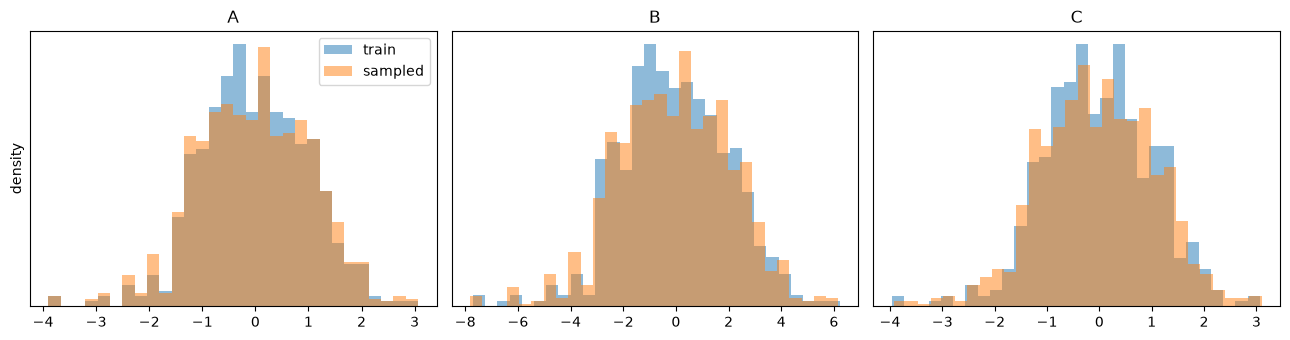

In [3]:
# viz: the observed data vs a fresh sample
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for j, (name, ax) in enumerate(zip(['A', 'B', 'C'], axes)):
    ax.hist(X[:, j], bins=30, alpha=0.5, density=True, label='train')
    ax.hist(Xs[:, j], bins=30, alpha=0.5, density=True, label='sampled')
    ax.set_title(name)
    ax.set_yticks([])
axes[0].set_ylabel('density')
axes[0].legend()
plt.tight_layout()

The sampled marginals match the training data — the DGP learned
the joint distribution of the chain.

## Interventions: the do-operator

`intervene(rows, nodes, values)` pins the given nodes, re-samples
their non-descendants' noise, and recomputes descendants through
the fitted mechanisms — causal surgery, not just column edits.

In [4]:
Xi = dgp.intervene(X.copy(), ['B'], [np.full(n, 10.0)], rng=default_rng(2))

print('B pinned at 10:', np.allclose(Xi[:, 1], 10.0))
print('A (ancestor) unchanged:', np.allclose(Xi[:, 0], X[:, 0]))
print('C follows do(B=10): mean =', np.round(Xi[:, 2].mean(), 2),
      '(theory ~5)')

B pinned at 10: True
A (ancestor) unchanged: True
C follows do(B=10): mean = 5.02 (theory ~5)


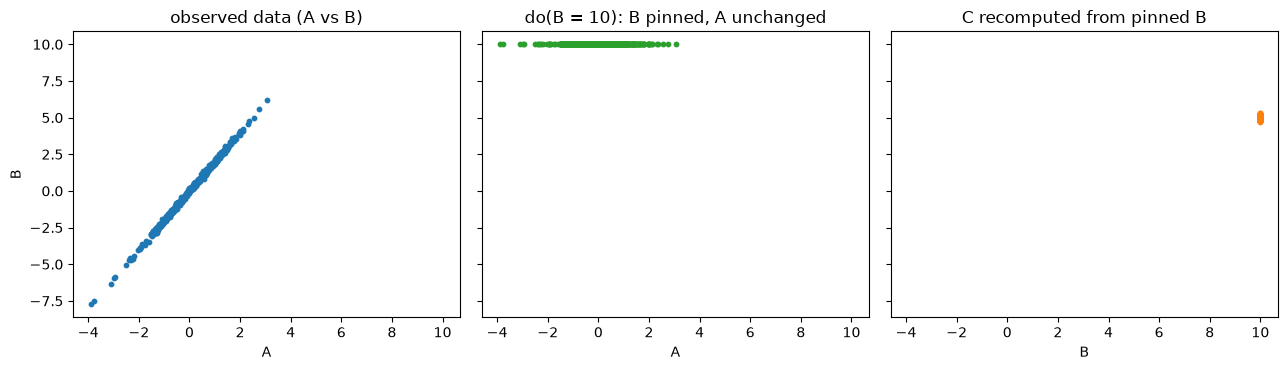

In [5]:
# viz: do(B = 10) breaks the A-B link and re-anchors C
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharex=True, sharey=True)
axes[0].scatter(X[:, 0], X[:, 1], s=10, color='C0')
axes[0].set_title('observed data (A vs B)')
axes[1].scatter(Xi[:, 0], Xi[:, 1], s=10, color='C2')
axes[1].set_title('do(B = 10): B pinned, A unchanged')
axes[2].scatter(Xi[:, 1], Xi[:, 2], s=10, color='C1')
axes[2].set_title('C recomputed from pinned B')
for ax in axes:
    ax.set_xlabel('A' if ax is not axes[2] else 'B')
axes[0].set_ylabel('B')
plt.tight_layout()

## Plugging a DGP into a causal generator

Any DGP works with every causal generator. The generator performs
the intervention itself (severing incoming edges of the
perturbation nodes, fresh noise for ancestors, recomputing
descendants through the DGP).

In this example we inject outliers values in node A and these values propagate through the SCM to B and C.

In [6]:
from badgers.core.selectors import AlwaysSelector
from badgers.generators.tabular_data.outliers.causal import CausalOutlierPropagationGenerator

rng = default_rng(0)
gen = CausalOutlierPropagationGenerator(random_generator=rng, dgp=dgp)
Xt = gen.generate(X, selector=AlwaysSelector([0]), n_outliers=5)

labels = gen.get_outliers_labels()
print('shape:', X.shape, '->', Xt.shape, '| outliers:', int(labels.sum()))
print('original rows unchanged:', np.allclose(Xt[:n], X))

shape: (500, 3) -> (505, 3) | outliers: 5
original rows unchanged: True


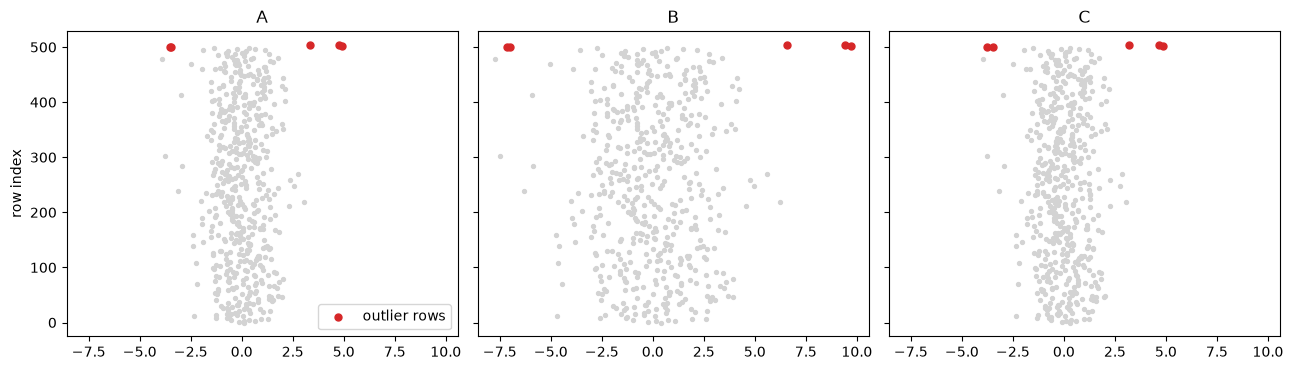

In [7]:
# viz: outliers injected at A, propagated down the chain
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharex=True, sharey=True)
for j, (name, ax) in enumerate(zip(['A', 'B', 'C'], axes)):
    ax.scatter(X[:, j], np.arange(n), s=8, color='lightgray')
    idx = np.flatnonzero(labels)
    ax.scatter(Xt[idx, j], idx, s=25, color='C3', label='outlier rows')
    ax.set_title(name)
axes[0].set_ylabel('row index')
axes[0].legend()
plt.tight_layout()

## Building the SCM externally: dowhy-gcm

`GcmSCMDGP` wraps a dowhy-gcm `StructuralCausalModel` built
outside badgers: assign a mechanism per node with dowhy-gcm's own
API, then hand the whole model over. badgers runs the graph and
exposes `fit`/`sample`/`intervene` — dowhy-gcm stays the home of
the mechanism definitions.

In [8]:
import dowhy.gcm as gcm

# 1. build the SCM with dowhy-gcm's own API
scm = gcm.StructuralCausalModel(graph)
scm.set_causal_mechanism('A', gcm.EmpiricalDistribution())
scm.set_causal_mechanism('B', gcm.AdditiveNoiseModel(
    prediction_model=gcm.ml.create_linear_regressor()))
scm.set_causal_mechanism('C', gcm.AdditiveNoiseModel(
    prediction_model=gcm.ml.create_linear_regressor()))

# 2. hand it to badgers — fit fits the SCM's mechanisms on X
from badgers.core.dgp.backends import GcmSCMDGP

gcm_dgp = GcmSCMDGP(scm, column_mapping).fit(X)
Xs_gcm = gcm_dgp.sample(rng=np.random.default_rng(0), n=100)
print('sampled:', Xs_gcm.shape, '| marginal means:',
      np.round(Xs_gcm.mean(axis=0), 2), 'vs train', np.round(X.mean(axis=0), 2))

# 3. interventions run through the same SCM
Xi_gcm = gcm_dgp.intervene(X[:50].copy(), ['B'],
                           [np.full(50, 10.0)], rng=np.random.default_rng(1))
assert np.allclose(Xi_gcm[:, 1], 10.0)
print('C after do(B=10) ~', round(float(Xi_gcm[:, 2].mean()), 2), '(theory ~ 5)')

# 4. and it plugs into causal generators like any other DGP
gen_gcm = CausalOutlierPropagationGenerator(
    random_generator=np.random.default_rng(0), dgp=gcm_dgp)
Xt_gcm = gen_gcm.generate(X, selector=AlwaysSelector([0]), n_outliers=5)
print('generator:', X.shape, '->', Xt_gcm.shape)


Fitting causal models:   0%|          | 0/3 [00:00<?, ?it/s]

Fitting causal mechanism of node A:   0%|          | 0/3 [00:00<?, ?it/s]

Fitting causal mechanism of node B:   0%|          | 0/3 [00:00<?, ?it/s]

Fitting causal mechanism of node C:   0%|          | 0/3 [00:00<?, ?it/s]

Fitting causal mechanism of node C: 100%|██████████| 3/3 [00:00<00:00, 378.05it/s]

sampled: (100, 3) | marginal means: [0.04 0.08 0.03] vs train [-0.03 -0.06 -0.03]
C after do(B=10) ~ 5.01 (theory ~ 5)
generator: (500, 3) -> (505, 3)


## Building the SCM externally: PyMC

`PyMCSCMDGP` wraps a user-written `pm.Model`: the structural nodes
are **observed** RVs named in `column_mapping`, and the structural
functions live in the distribution parameters (here `sin(A)` in the
mean of `B`). One joint `pm.sample` keeps the full posterior —
every cascade pins ONE coherent draw, same seed, same draw.

In [9]:
import pymc as pm

# 1. write the SCM as a PyMC model: structural nodes observed,
#    free RVs are the unknown parameters, functions go in the params
with pm.Model() as scm_pm:
    mu_A = pm.Normal('mu_A', 0, 2)
    sigma_A = pm.HalfNormal('sigma_A', 1)
    A = pm.Normal('A', mu=mu_A, sigma=sigma_A, observed=X[:, 0])
    sigma_B = pm.HalfNormal('sigma_B', 1)
    B = pm.Normal('B', mu=pm.math.sin(A), sigma=sigma_B, observed=X[:, 1])
    beta_C = pm.Normal('beta_C', 0, 2)
    sigma_C = pm.HalfNormal('sigma_C', 1)
    C = pm.Normal('C', mu=beta_C * B, sigma=sigma_C, observed=X[:, 2])

# 2. hand it to badgers — one joint MCMC run, full posterior kept
from badgers.core.dgp.backends import PyMCSCMDGP

pm_scm_dgp = PyMCSCMDGP(scm_pm, column_mapping, n_draws=200).fit(X)
Xs_pm = pm_scm_dgp.sample(rng=np.random.default_rng(0), n=100)
print('sampled:', Xs_pm.shape)

r1 = pm_scm_dgp.sample(rng=np.random.default_rng(0), n=100)
r2 = pm_scm_dgp.sample(rng=np.random.default_rng(1), n=100)
print('same seed -> identical output:', np.allclose(Xs_pm, r1))
print('different seed -> different output:', not np.allclose(r1, r2))
assert np.allclose(Xs_pm, r1)
assert not np.allclose(r1, r2)

# 3. interventions run through the posterior
Xi_pm = pm_scm_dgp.intervene(X[:50].copy(), ['B'],
                             [np.full(50, 10.0)], rng=np.random.default_rng(1))
assert np.allclose(Xi_pm[:, 1], 10.0)
print('C after do(B=10) ~', round(float(Xi_pm[:, 2].mean()), 2), '(theory ~ 5)')

# 4. and it plugs into causal generators like any other DGP
gen_pm = CausalOutlierPropagationGenerator(
    random_generator=np.random.default_rng(0), dgp=pm_scm_dgp)
Xt_pm = gen_pm.generate(X, selector=AlwaysSelector([0]), n_outliers=5)
print('generator:', X.shape, '->', Xt_pm.shape)


g++ not available, if using conda: `conda install gxx`


Initializing NUTS using jitter+adapt_diag...


Sequential sampling (1 chains in 1 job)


NUTS: [mu_A, sigma_A, sigma_B, beta_C, sigma_C]


Sampling 1 chain for 100 tune and 200 draw iterations (100 + 200 draws total) took 0 seconds.


sampled: (100, 3)
same seed -> identical output: True
different seed -> different output: True
C after do(B=10) ~ 5.03 (theory ~ 5)
generator: (500, 3) -> (505, 3)


## Takeaways

- One protocol: `fit(X)`, then `sample(rng, n)` and
  `intervene(rows, nodes, values, rng=...)` — identical across
  backends.
- `GcmSCMDGP` uses a `dowhy.gcm.StructuralCausalModel` 
- `PyMCSCMDGP` uses a `pm.Model` 
